# TP 10 — Réseau de neurones (ANN)
**Deep Learning · Réseau dense · Rétropropagation**



| Exemple | Diapos | Problème |
|---|---|---|
| Exemple 1 | 72, 74 | Classification : un étudiant a révisé 2 h, réussira-t-il ? (1 exemple, 3 epochs) |
| Exemple 2 | 73, 75 | Epochs et batchs : 4 étudiants, `batch_size = 2`, 300 epochs |
| Exemple 3 | 76 | Régression : une pub de 2 (centaines de TND) → ventes |

Réseau **1 → 1 → 1** : un neurone caché (ReLU) puis un neurone de sortie (sigmoïde ou linéaire).

**Objectifs** : programmer **en Python pur** le forward, la perte, la rétropropagation et la mise à jour, et les appliquer aux exemples des diapos ; puis refaire les mêmes entraînements avec **Keras** (mêmes poids de départ) et comparer les deux implémentations.

## Rappel de cours

**Forward** (calcul de la sortie) :
$$a = \text{ReLU}(w_1 x + b_1) = \max(0 ; w_1 x + b_1) \qquad p = \sigma(w_2 a + b_2) \ \ (\text{ou } \hat y = w_2 a + b_2 \text{ en régression})$$

**Perte** : $-\ln p$ si $y = 1$ ($-\ln(1-p)$ si $y = 0$) ; $(y - \hat y)^2$ en régression.

**Rétropropagation** (dérivation en chaîne, de la sortie vers l’entrée) :
$$\delta = p - y \ \ (\text{ou } \delta = -2(y - \hat y)) \qquad \nabla w_2 = \delta\,a \quad \nabla b_2 = \delta \quad \nabla w_1 = \delta\,w_2\,x \quad \nabla b_1 = \delta\,w_2$$
(les deux derniers valent 0 si le neurone ReLU est éteint, c’est-à-dire si $w_1 x + b_1 \le 0$.)

**Mise à jour** : poids $:=$ poids $- \eta \times$ gradient. Avec un batch de plusieurs exemples, on prend la **moyenne** des gradients.

**Vocabulaire** : une **itération** = un batch → forward → perte → backprop → mise à jour ; une **epoch** = toutes les données vues une fois. Les poids ne repartent **jamais** de zéro.

In [ ]:
import math

---
# Partie A — Implémentation from scratch (Python pur)

### Question 1 — Programmer le forward et la rétropropagation du réseau 1 → 1 → 1
**Réponse.** Les poids sont rangés dans une liste `[w1, b1, w2, b2]`. La fonction `gradients` renvoie la moyenne des gradients sur un batch.

In [ ]:
sigmoide = lambda z: 1 / (1 + math.exp(-z))

def forward(poids, x, sortie="sigmoide"):
    w1, b1, w2, b2 = poids
    z1 = w1 * x + b1
    a = max(0.0, z1)                        # ReLU
    z2 = w2 * a + b2
    return z1, a, (sigmoide(z2) if sortie == "sigmoide" else z2)

def perte(y, p, sortie="sigmoide"):
    if sortie == "sigmoide":
        return -math.log(p) if y == 1 else -math.log(1 - p)
    return (y - p) ** 2

def gradients(poids, batch, sortie="sigmoide"):
    w1, b1, w2, b2 = poids
    g = [0.0, 0.0, 0.0, 0.0]
    for x, y in batch:
        z1, a, p = forward(poids, x, sortie)
        delta = (p - y) if sortie == "sigmoide" else -2 * (y - p)
        relu_actif = 1.0 if z1 > 0 else 0.0
        g[0] += delta * w2 * relu_actif * x     # ∇w1
        g[1] += delta * w2 * relu_actif         # ∇b1
        g[2] += delta * a                       # ∇w2
        g[3] += delta                           # ∇b2
    return [gi / len(batch) for gi in g]

def mise_a_jour(poids, grads, eta):
    return [p - eta * g for p, g in zip(poids, grads)]

## Exemple 1 : un étudiant, x = 2 h, y = 1 (diapos 72 et 74)

Poids de départ $(w_1 ; b_1 ; w_2 ; b_2) = (1 ; 0 ; 1 ; -3)$, $\eta = 0{,}2$, 3 epochs. Un seul exemple : 1 epoch = 1 itération.

### Question 2 — Epoch 1 détaillée
**Réponse.**
- Forward : $z_1 = 1\times 2 + 0 = 2$ ; $a = 2$ ; $p = \sigma(1\times 2 - 3) = \sigma(-1) = 0{,}27$
- Perte $= -\ln 0{,}27 = 1{,}31$ ; $\delta = 0{,}27 - 1 = -0{,}73$
- Gradients : $\nabla w_2 = -0{,}73\times 2 = -1{,}46$ ; $\nabla b_2 = -0{,}73$ ; $\nabla w_1 = -0{,}73\times 1\times 2 = -1{,}46$ ; $\nabla b_1 = -0{,}73$
- Mise à jour : $w_2 = 1{,}29$ ; $b_2 = -2{,}85$ ; $w_1 = 1{,}29$ ; $b_1 = 0{,}15$

In [ ]:
poids = [1.0, 0.0, 1.0, -3.0]
z1, a, p = forward(poids, 2)
print(f"Forward : z1 = {z1} ; a = ReLU(z1) = {a} ; p = σ(w2·a + b2) = {p:.4f}")
print(f"Perte   : −ln p = {perte(1, p):.4f}")
g = gradients(poids, [(2, 1)])
print("Gradients :", {nom: round(gi, 4) for nom, gi in zip(["∇w1", "∇b1", "∇w2", "∇b2"], g)})
poids = mise_a_jour(poids, g, 0.2)
print("Poids après epoch 1 :", {nom: round(v, 4) for nom, v in zip(["w1", "b1", "w2", "b2"], poids)})

Forward : z1 = 2.0 ; a = ReLU(z1) = 2.0 ; p = σ(w2·a + b2) = 0.2689
Perte   : −ln p = 1.3133
Gradients : {'∇w1': -1.4621, '∇b1': -0.7311, '∇w2': -1.4621, '∇b2': -0.7311}
Poids après epoch 1 : {'w1': 1.2924, 'b1': 0.1462, 'w2': 1.2924, 'b2': -2.8538}


### Question 3 — Epochs 2 et 3
**Réponse.** On répète la même boucle : chaque epoch part des poids laissés par la précédente. La probabilité de réussite monte (0,27 → 0,66 → 0,87 → 0,92) et la perte baisse (1,31 → 0,41 → 0,14 → 0,08).

In [ ]:
def entrainer_un_exemple(epochs=3):
    poids = [1.0, 0.0, 1.0, -3.0]
    lignes = []
    for e in range(epochs + 1):
        _, _, p = forward(poids, 2)
        lignes.append((e, *poids, p, perte(1, p)))
        poids = mise_a_jour(poids, gradients(poids, [(2, 1)]), 0.2)
    return lignes

exact = entrainer_un_exemple()
print("Epoch |   w1      b1      w2      b2    |   p      perte")
for e, w1, b1, w2, b2, p, L in exact:
    print(f"  {e}   | {w1:6.3f}  {b1:6.3f}  {w2:6.3f}  {b2:6.3f} | {p:6.3f}  {L:6.3f}")

Epoch |   w1      b1      w2      b2    |   p      perte
  0   |  1.000   0.000   1.000  -3.000 |  0.269   1.313
  1   |  1.292   0.146   1.292  -2.854 |  0.663   0.411
  2   |  1.467   0.233   1.477  -2.786 |  0.869   0.141
  3   |  1.544   0.272   1.560  -2.760 |  0.923   0.080


## Exemple 2 : 4 étudiants, epochs et batchs (diapos 73 et 75)

| $x$ (h) | 1 | 2 | 3 | 4 |
|---|---|---|---|---|
| $y$ | 0 | 0 | 1 | 1 |

Mêmes poids de départ $(1 ; 0 ; 1 ; -3)$, $\eta = 0{,}2$, `batch_size = 2` → **2 itérations par epoch** : batch {1 h ; 3 h} puis batch {2 h ; 4 h}. Le gradient d’un batch est la **moyenne** des gradients de ses exemples.

### Question 4 — Itérations 1 et 2 (epoch 1)
**Réponse.**
- Itération 1, batch {1 ; 3} : $p = 0{,}12$ et $0{,}50$ ; moyennes $\nabla w_1 = (0{,}12 - 1{,}50)/2 = -0{,}69$ ; $\nabla b_1 = -0{,}19$ ; $\nabla w_2 = -0{,}69$ ; $\nabla b_2 = -0{,}19$ → $(1{,}14 ; 0{,}04 ; 1{,}14 ; -2{,}96)$
- Itération 2, batch {2 ; 4}, en partant de ces poids → $(1{,}09 ; 0{,}00 ; 1{,}08 ; -2{,}99)$
- Perte moyenne sur les 4 étudiants : 0,36 → 0,30

In [ ]:
etudiants = [(1, 0), (2, 0), (3, 1), (4, 1)]
batchs = [[(1, 0), (3, 1)], [(2, 0), (4, 1)]]

def perte_moyenne(poids):
    return sum(perte(y, forward(poids, x)[2]) for x, y in etudiants) / len(etudiants)

poids = [1.0, 0.0, 1.0, -3.0]
print(f"Perte de départ (4 étudiants) : {perte_moyenne(poids):.4f}")
g = gradients(poids, batchs[0])
print("Itération 1, batch {1 h ; 3 h} : gradients moyens =", [round(v, 4) for v in g])
poids = mise_a_jour(poids, g, 0.2)
print("   poids après itération 1 :", [round(v, 4) for v in poids])
g = gradients(poids, batchs[1])
print("Itération 2, batch {2 h ; 4 h} : gradients moyens =", [round(v, 4) for v in g])
poids = mise_a_jour(poids, g, 0.2)
print("   poids après itération 2 :", [round(v, 4) for v in poids])
print(f"Perte fin d'epoch 1 : {perte_moyenne(poids):.4f}")

Perte de départ (4 étudiants) : 0.3616
Itération 1, batch {1 h ; 3 h} : gradients moyens = [-0.6904, -0.1904, -0.6904, -0.1904]
   poids après itération 1 : [1.1381, 0.0381, 1.1381, -2.9619]
Itération 2, batch {2 h ; 4 h} : gradients moyens = [0.2619, 0.1846, 0.2681, 0.1622]
   poids après itération 2 : [1.0857, 0.0012, 1.0845, -2.9944]
Perte fin d'epoch 1 : 0.2999


### Question 5 — 300 epochs (600 itérations)
**Réponse.** On répète la boucle « pour chaque epoch, pour chaque batch ». Les poids ne repartent jamais de zéro : chaque itération part des poids laissés par la précédente. Après 300 epochs, la perte vaut 0,01 et $p = 0{,}01 ; 0{,}02 ; 0{,}98 ; 1{,}00$.

In [ ]:
poids = [1.0, 0.0, 1.0, -3.0]
for epoch in range(1, 301):
    for batch in batchs:                     # 2 itérations par epoch
        poids = mise_a_jour(poids, gradients(poids, batch), 0.2)
    if epoch in (1, 2, 10, 50, 100, 300):
        print(f"epoch {epoch:>3} (itération {2 * epoch:>3}) : poids = {[round(v, 2) for v in poids]} ; perte = {perte_moyenne(poids):.3f}")
p_final = [forward(poids, x)[2] for x, _ in etudiants]
print("p après 300 epochs pour 1, 2, 3, 4 h :", [round(p, 3) for p in p_final])
poids_ann300 = poids

epoch   1 (itération   2) : poids = [1.09, 0.0, 1.08, -2.99] ; perte = 0.300
epoch   2 (itération   4) : poids = [1.11, -0.02, 1.11, -3.01] ; perte = 0.291
epoch  10 (itération  20) : poids = [1.18, -0.25, 1.19, -3.18] ; perte = 0.260
epoch  50 (itération 100) : poids = [1.39, -1.26, 1.68, -3.81] ; perte = 0.150
epoch 100 (itération 200) : poids = [1.6, -2.18, 2.31, -4.3] ; perte = 0.078
epoch 300 (itération 600) : poids = [2.0, -3.66, 3.76, -4.98] ; perte = 0.013
p après 300 epochs pour 1, 2, 3, 4 h : [0.007, 0.024, 0.979, 1.0]


## Exemple 3 : régression, publicité → ventes (diapo 76)

Une pub de $x = 2$ (centaines de TND) a rapporté $y = 10$. Même réseau, mais **sortie linéaire** et perte $(y - \hat y)^2$. Poids de départ $(1 ; 0 ; 1 ; 0)$, $\eta = 0{,}01$, 3 epochs.

### Question 6 — Les 3 epochs
**Réponse.**
- Epoch 1 : $\hat y = 2$ ; perte $= 64$ ; $\delta = -2\times(10 - 2) = -16$ ; gradients $-32 ; -16 ; -32 ; -16$ → $(1{,}32 ; 0{,}16 ; 1{,}32 ; 0{,}16)$
- Puis $\hat y$ se rapproche de la cible 10 : 2 → 3,86 → 6,29 → 8,53 ; la perte baisse : 64 → 37,7 → 13,8 → 2,2

In [ ]:
def entrainer_regression():
    poids = [1.0, 0.0, 1.0, 0.0]
    lignes = []
    for e in range(4):
        y_pred = forward(poids, 2, "lineaire")[2]
        lignes.append((e, *poids, y_pred, perte(10, y_pred, "lineaire")))
        poids = mise_a_jour(poids, gradients(poids, [(2, 10)], "lineaire"), 0.01)
    return lignes

g0 = gradients([1.0, 0.0, 1.0, 0.0], [(2, 10)], "lineaire")
print("Gradients epoch 1 :", {nom: round(gi, 4) for nom, gi in zip(["∇w1", "∇b1", "∇w2", "∇b2"], g0)})
reg_exact = entrainer_regression()
for e, w1, b1, w2, b2, y_pred, L in reg_exact:
    print(f"epoch {e} : poids = {[round(v, 3) for v in (w1, b1, w2, b2)]} ; ŷ = {y_pred:.3f} ; perte = {L:.3f}")

Gradients epoch 1 : {'∇w1': -32.0, '∇b1': -16.0, '∇w2': -32.0, '∇b2': -16.0}
epoch 0 : poids = [1.0, 0.0, 1.0, 0.0] ; ŷ = 2.000 ; perte = 64.000
epoch 1 : poids = [1.32, 0.16, 1.32, 0.16] ; ŷ = 3.856 ; perte = 37.749
epoch 2 : poids = [1.644, 0.322, 1.664, 0.283] ; ŷ = 6.292 ; perte = 13.751
epoch 3 : poids = [1.891, 0.446, 1.932, 0.357] ; ŷ = 8.525 ; perte = 2.175


---
# Partie B — Les mêmes entraînements avec Keras

### Question 7 — Construire le réseau dans Keras avec les mêmes poids de départ
**Réponse.** On reprend le code de la diapo 77 : `Dense(1, activation="relu")` puis `Dense(1, activation="sigmoid")`, l’optimiseur `SGD(learning_rate=0.2)` et la perte `binary_crossentropy`. Pour comparer, on impose les poids de départ avec `set_weights` et on garde l’ordre des exemples (`shuffle=False`).

Un *callback* enregistre les poids à la fin de chaque epoch.

In [ ]:
import numpy as np
import keras
from keras import layers

def creer_reseau(poids, sortie="sigmoid"):
    w1, b1, w2, b2 = poids
    model = keras.Sequential([keras.Input(shape=(1,)),
                              layers.Dense(1, activation="relu"),
                              layers.Dense(1, activation=sortie)])
    model.layers[0].set_weights([np.array([[w1]]), np.array([b1])])
    model.layers[1].set_weights([np.array([[w2]]), np.array([b2])])
    return model

def poids_keras(model):
    (k1, c1), (k2, c2) = model.layers[0].get_weights(), model.layers[1].get_weights()
    return [float(k1[0, 0]), float(c1[0]), float(k2[0, 0]), float(c2[0])]

class Historique(keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.poids = [poids_keras(self.model)]
    def on_epoch_end(self, epoch, logs=None):
        self.poids.append(poids_keras(self.model))

In [ ]:
# Exemple 1 : un étudiant, 3 epochs
m1 = creer_reseau([1, 0, 1, -3])
m1.compile(optimizer=keras.optimizers.SGD(learning_rate=0.2), loss="binary_crossentropy")
h1 = Historique()
m1.fit(np.array([[2.0]]), np.array([[1.0]]), epochs=3, batch_size=1, shuffle=False, verbose=0, callbacks=[h1])
for e, pk in enumerate(h1.poids):
    print(f"Keras epoch {e} : poids = {[round(v, 3) for v in pk]}")
p_keras_1 = float(m1.predict(np.array([[2.0]]), verbose=0)[0, 0])
print("p après 3 epochs :", round(p_keras_1, 3))

Keras epoch 0 : poids = [1.0, 0.0, 1.0, -3.0]
Keras epoch 1 : poids = [1.292, 0.146, 1.292, -2.854]
Keras epoch 2 : poids = [1.467, 0.233, 1.477, -2.786]
Keras epoch 3 : poids = [1.544, 0.272, 1.56, -2.76]
p après 3 epochs : 0.923


In [ ]:
# Exemple 2 : 4 étudiants, batch_size = 2, 300 epochs
# On range les étudiants dans l'ordre 1, 3, 2, 4 pour que les batchs soient {1 h ; 3 h} puis {2 h ; 4 h}
X4 = np.array([[1.0], [3.0], [2.0], [4.0]]); Y4 = np.array([[0.0], [1.0], [0.0], [1.0]])
m2 = creer_reseau([1, 0, 1, -3])
m2.compile(optimizer=keras.optimizers.SGD(learning_rate=0.2), loss="binary_crossentropy")
h2 = Historique()
m2.fit(X4, Y4, epochs=300, batch_size=2, shuffle=False, verbose=0, callbacks=[h2])
for e in [1, 2, 10, 50, 100, 300]:
    print(f"Keras epoch {e:>3} : poids = {[round(v, 2) for v in h2.poids[e]]}")
p_keras_4 = m2.predict(np.array([[1.0], [2.0], [3.0], [4.0]]), verbose=0).ravel()
print("p après 300 epochs :", p_keras_4.round(2))

Keras epoch   1 : poids = [1.09, 0.0, 1.08, -2.99]
Keras epoch   2 : poids = [1.11, -0.02, 1.11, -3.01]
Keras epoch  10 : poids = [1.18, -0.25, 1.19, -3.18]
Keras epoch  50 : poids = [1.39, -1.26, 1.68, -3.81]
Keras epoch 100 : poids = [1.6, -2.18, 2.31, -4.3]
Keras epoch 300 : poids = [2.0, -3.66, 3.76, -4.98]
p après 300 epochs : [0.01 0.02 0.98 1.  ]


In [ ]:
# Exemple 3 : régression, sortie linéaire, perte MSE, η = 0,01
m3 = creer_reseau([1, 0, 1, 0], sortie="linear")
m3.compile(optimizer=keras.optimizers.SGD(learning_rate=0.01), loss="mse")
h3 = Historique()
m3.fit(np.array([[2.0]]), np.array([[10.0]]), epochs=3, batch_size=1, shuffle=False, verbose=0, callbacks=[h3])
y_keras = float(m3.predict(np.array([[2.0]]), verbose=0)[0, 0])
print("Poids après 3 epochs :", [round(v, 3) for v in h3.poids[-1]], "| ŷ =", round(y_keras, 3))

Poids après 3 epochs : [1.891, 0.446, 1.932, 0.357] | ŷ = 8.525


---
# Partie C — Comparaison et validation
### Question 8 — Python pur et Keras donnent-ils les mêmes poids ?
**Réponse.** On compare les poids et les prédictions obtenus par les deux implémentations. Keras calcule en `float32` : on accepte un écart de l’ordre de $10^{-4}$.

In [ ]:
import pandas as pd
noms = ["w1", "b1", "w2", "b2"]
lignes = [(f"Ex.1 {n} après 3 epochs", exact[3][1 + i], h1.poids[3][i]) for i, n in enumerate(noms)]
lignes += [("Ex.1 p après 3 epochs", exact[3][5], p_keras_1)]
lignes += [(f"Ex.2 {n} après 300 epochs", poids_ann300[i], h2.poids[300][i]) for i, n in enumerate(noms)]
lignes += [(f"Ex.2 p({x} h) après 300 epochs", forward(poids_ann300, x)[2], p_keras_4[x - 1]) for x in (1, 2, 3, 4)]
lignes += [(f"Ex.3 {n} après 3 epochs", reg_exact[3][1 + i], h3.poids[3][i]) for i, n in enumerate(noms)]
lignes += [("Ex.3 ŷ après 3 epochs", reg_exact[3][5], y_keras)]
display(pd.DataFrame(lignes, columns=["Grandeur", "Python pur", "Keras"]).round(4))

assert np.allclose([e[1:5] for e in exact], h1.poids, atol=1e-4)
assert np.allclose(poids_ann300, h2.poids[300], atol=1e-3)
assert np.allclose([e[1:5] for e in reg_exact], h3.poids, atol=1e-4)
print("===== Python pur = Keras (mêmes poids epoch après epoch, aux arrondis float32 près)")

,Grandeur,Python pur,Keras
0,Ex.1 w1 après 3 epochs,1.5443,1.5443
1,Ex.1 b1 après 3 epochs,0.2721,0.2721
2,Ex.1 w2 après 3 epochs,1.5597,1.5597
3,Ex.1 b2 après 3 epochs,-2.7601,-2.7601
4,Ex.1 p après 3 epochs,0.9228,0.9228
5,Ex.2 w1 après 300 epochs,2.0025,2.0025
6,Ex.2 b1 après 300 epochs,-3.6630,-3.6630
7,Ex.2 w2 après 300 epochs,3.7637,3.7637
8,Ex.2 b2 après 300 epochs,-4.9766,-4.9766
9,Ex.2 p(1 h) après 300 epochs,0.0069,0.0069


✅ Python pur = Keras (mêmes poids epoch après epoch, aux arrondis float32 près)


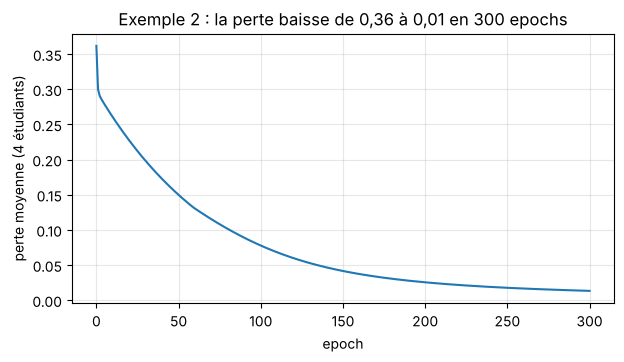

In [ ]:
import matplotlib.pyplot as plt
pertes_ep = []
w = [1.0, 0.0, 1.0, -3.0]
for epoch in range(301):
    pertes_ep.append(perte_moyenne(w))
    for batch in batchs:
        w = mise_a_jour(w, gradients(w, batch), 0.2)
plt.figure(figsize=(7, 3.5))
plt.plot(pertes_ep); plt.xlabel("epoch"); plt.ylabel("perte moyenne (4 étudiants)")
plt.title("Exemple 2 : la perte baisse de 0,36 à 0,01 en 300 epochs"); plt.grid(alpha=0.3); plt.show()

## Conclusion



**À retenir**
- Entraîner = répéter **forward → perte → rétropropagation → mise à jour**.
- Batch = plusieurs exemples, gradient moyen ; epoch = toutes les données vues une fois ; itérations par epoch $= \lceil N/B \rceil$.
- Les poids ne repartent jamais de zéro : chaque mise à jour part des poids laissés par la précédente.